# PHYS - 4147 Homework 6

##Precession of Mercury

One of the leading observational drawbacks of Newtonian Gravity was that it could not explain the precession of Mercury. Thus, it became one of the first tests of General Relativity. In this notebook, we will try to pull observational data of Mercury from NASA's database, and try and calculate the precession value for Mercury

Run the cell below to install the package ```astroquery``` to pull observational data for Mercury from NASA JPL, especially if you are running this on Google Colab

In [ ]:
!pip install astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 26.5 MB/s eta 0:00:00


In [ ]:
## Try importing the package you just installed to see if it worked!
from astroquery.jplhorizons import Horizons

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#How to calculate the eccentricity from observational data?
If we have the position vector of Mercury $\vec{r} = (x,y,z)$ and it's velocity vector $\vec{v} = (v_x,v_y,v_z)$, we can figure out the "eccentricity vector". The eccentricity vector points from the sun to the position of closest approach Mercury has to the sun. In a way, it measures the "ovalness" of the orbit. And, as we know, the "oval" of the Mercury moves around the sun with time. We are going to calculate by how much, given the observed values.

The eccentricity vector can be calculated using this formula:

$
\begin{equation}
\vec{e} = \frac{ \vec{v} \times \vec{h} }{\mu} - \frac{\vec{r}}{|\vec{r}|}
\end{equation}
$

where $\vec{v}$ is the velocity vector, $\vec{h}$ is the angular momentum vector $\vec{h} = \vec{r} \times \vec{v}$, $\vec{r}$ is the position vector of Mercury with respect to the sun and $\mu = GM_{sun}$ in units of Astronomical Units (AU) and days. We used AU and days becasue our observations in the dataset are in this unit.

In [ ]:
#define the ID of the planet based on International Astronomical
planet_id=199

#define the location with respect to which you want your coordinates
location='@sun'

#constant: Mu
Mu = 2.959122082855911e-4 # GM of the Sun in AU^3 / day^2 (astroquery vectors() returns AU and AU/day)

# Problem 1
How long a data would we require? Fill in the start and end year in the cell below. Hint: the plot of $\theta$ vs $time$ should look like a line, where $\theta$ measures the angle by which the perihilion preccesses.

Bonus: Try different values of start/end years and see how the precession value / error changes at the end.

In [30]:
#define the years for which we will fetch observational data (choose any year from between 1600 and 2026)
start_year = 1600
end_year = 2026
step="4d"

duration = end_year - start_year

## Eccentricity vector function

In [31]:
def eccentricity_vectors(r, v, mu=Mu):
    """r, v: arrays of shape (N, 3). Returns eccentricity vectors, shape (N, 3)."""
    h = np.cross(r, v)
    r_norm = np.linalg.norm(r, axis=1)[:, None]
    return np.cross(v, h) / mu - r / r_norm

##Fetch the data

In [32]:
## Initialize the dataset for mercury
obj = Horizons(
            id="199",             # Mercury
            location="@sun",      # heliocentric
            epochs={"start": f"{start_year}-01-01", "stop": f"{end_year}-01-01", "step": "4d"},
        )

vec = obj.vectors()

## check if the data fetch worked!
print("You fetched data for the planet:", vec["targetname"][0].split()[0])

You fetched data for the planet: Mercury


## Make the vectors $\vec{r}$, $\vec{v}$ (as well as the time array t)

The position vector $\vec{r}$ and the velocity vector $\vec{v}$ is with respect to the sun

In [33]:
x,y,z = np.array(vec["x"]),np.array(vec["y"]),np.array(vec["z"])
vx,vy,vz = np.array(vec["vx"]),np.array(vec["vy"]),np.array(vec["vz"])

r = np.column_stack([x, y, z])
v = np.column_stack([vx, vy, vz])

jd = np.array(vec["datetime_jd"]) ##this quantity is in Julian Days.
## We convert it to Julian years. Jan 1 2000 was Julian Day 2451545.0, and each Julian year has 36525.0 days.
time_array = (jd - 2451545.0) / 36525.0 ##this time array is in terms of centuries from Jan 1 2000.

## Calculate the eccentricity for each data point

In [34]:
ecc = eccentricity_vectors(r,v,mu=Mu) ##this is in radians

##unwrap the x and y component of the eccentricity work
ecc_x, ecc_y = ecc[:, 0], ecc[:, 1]


## Calculate the angle

$
\theta = tan^{-1}(\frac{e_y}{e_x})
$

In [35]:
theta = np.unwrap(np.arctan2(ecc_y,ecc_x))

##convert it to degrees, and then to arc seconds by multiplying by 3600 (i.e each degree has 3600 arc seconds)
theta = np.rad2deg(theta) * 3600

Text(0.5, 1.0, 'Plot for 426 years')

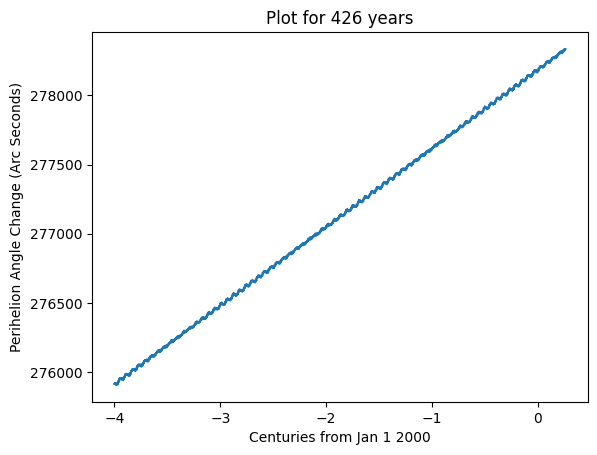

In [36]:
plt.plot(time_array, theta)
plt.xlabel("Centuries from Jan 1 2000")
plt.ylabel("Perihelion Angle Change (Arc Seconds)")
plt.title(f"Plot for {duration} years")

### We have a plot!! Its a plot of $\theta$ vs century. We need to figure out the value of precession in "degrees/centure" i.e the slope of the plot we have here. We fit a straight line to this curve and the slope would be value we are after. Let's do that.

In [37]:
coeffs, cov = np.polyfit(time_array, theta, 1, cov=True)
slope = coeffs[0]
slope_err = np.sqrt(cov[0, 0])
print(f"Total perihelion precession: {slope:.3f} +/- {slope_err:.3f} arc seconds/century")

Total perihelion precession: 569.069 +/- 0.029 arc seconds/century


## Problem 2
Is your best case plot above actually a straight line? Can you explain why not?

## Problem 3
Look up the observed value of Mercury's precession, and the value General Relativity predicts. Does your value above agree with these? Why/why not?

## Lets vizualize the orbit of mercury now

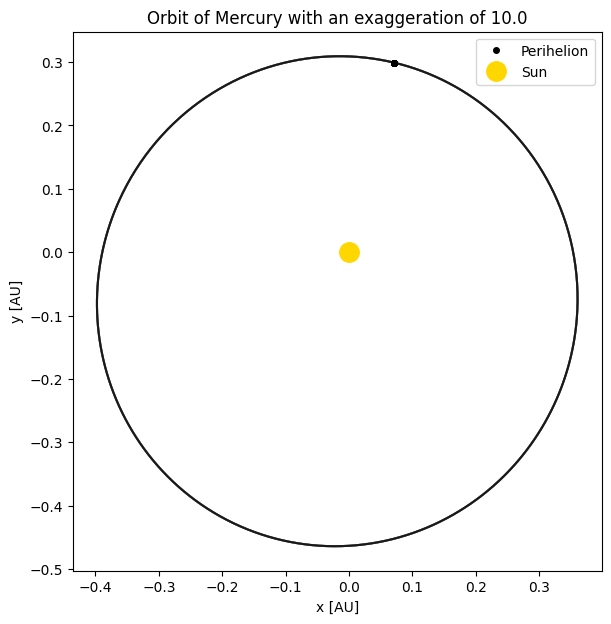

In [38]:
exaggeration = 1e1     # this variable exaggerates the effect of precession for visual purposes
number_of_orbits = 10   # the number of orbits of mercury you want to plot

e = np.linalg.norm(ecc, axis=1).mean()                        # eccentricity
p = (np.linalg.norm(np.cross(r, v), axis=1)**2 / Mu).mean()   # sets the orbit size
shift = np.deg2rad(slope/3600) * (87.97/36525) * exaggeration  # perihelion shift per orbit (rad)
theta0 = np.arctan2(ecc_y[0], ecc_x[0])                       # starting perihelion direction

nu = np.linspace(0, 2*np.pi, 500)
plt.figure(figsize=(7, 7))
for k in range(number_of_orbits):
    th = theta0 + k*shift
    rho = p / (1 + e*np.cos(nu))
    plt.plot(rho*np.cos(nu+th), rho*np.sin(nu+th), color='k', alpha=0.2)
    r_peri = p / (1 + e)
    plt.plot(r_peri*np.cos(th), r_peri*np.sin(th), "ko", ms=4,
             label="Perihelion" if k == 0 else None)           # labeled only once
plt.plot(0, 0, "o", color="gold", ms=14, label="Sun")          # Sun at the focus
plt.gca().set_aspect("equal")
plt.legend()
plt.xlabel("x [AU]")
plt.ylabel("y [AU]")
plt.title(f"Orbit of Mercury with an exaggeration of {exaggeration}")
plt.show()

## Problem 4
Can you see the perihilion point moving? How about if you make the "exaggerate" variable bigger? Why is this happening?

## Problem 5
Attach your plot of $\theta$ vs century and the orbit of Mercury